In [15]:
import json
with open("COCOFreeView_fixations_trainval.json","r")as f:
      data = json.load(f)
print("Total trials loaded:",len(data))
print("First trial keys:",data[0].keys())
print("First trail samples:",data)

Total trials loaded: 43048
First trial keys: dict_keys(['name', 'subject', 'condition', 'X', 'Y', 'T', 'length', 'split', 'fixOnTarget', 'correct'])
First trail samples: [{'name': '000000128398.jpg', 'subject': 101, 'condition': 'freeview', 'X': [821.5, 957.1, 933.4, 748.6, 530.2, 858.2, 1146.2, 1190.6, 986.3, 816.2, 724.0, 920.4, 1079.9, 752.7, 735.2], 'Y': [559.2, 557.7, 531.1, 525.6, 561.4, 565.2, 320.9, 297.0, 422.6, 491.4, 497.2, 515.5, 294.2, 440.3, 549.1], 'T': [316.0, 148.0, 123.0, 224.0, 445.0, 225.0, 241.0, 410.0, 177.0, 443.0, 629.0, 224.0, 206.0, 216.0, 211.0], 'length': 15, 'split': 'train', 'fixOnTarget': False, 'correct': 1}, {'name': '000000128398.jpg', 'subject': 102, 'condition': 'freeview', 'X': [821.8, 651.4, 658.9, 638.0, 795.2, 840.8, 898.8, 932.8, 917.4, 1139.4, 1036.4, 1040.4, 908.6, 1016.2, 1049.4, 918.6, 963.2, 1004.0], 'Y': [509.6, 289.2, 347.8, 446.6, 605.1, 619.7, 277.3, 345.9, 419.0, 282.2, 551.5, 619.1, 638.3, 303.4, 352.6, 437.6, 453.8, 457.9], 'T': [429

/tmp/ipykernel_505/2365751023.py:20: RuntimeWarning: invalid value encountered in sqrt
  saccades = np.sqrt(dx*2 + dy*2)


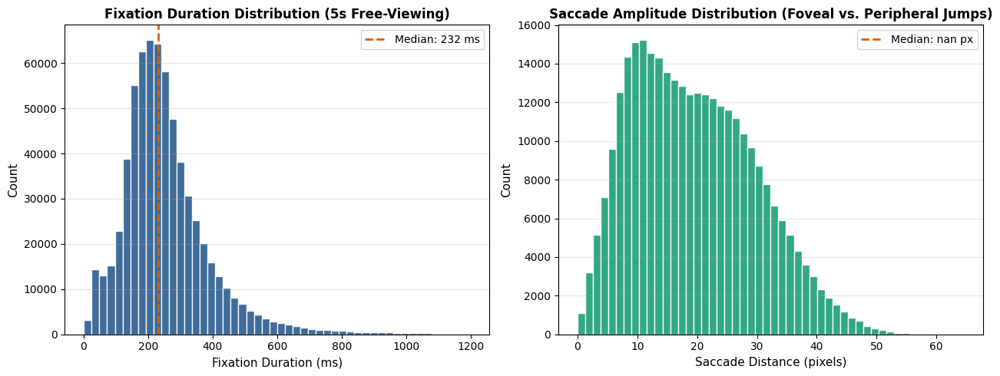

Total fixations analyzed: 665,005
Median fixation duration: 232.0 ms
Median saccade amplitude: 18.5 pixels


In [16]:
import json
with open("COCOFreeView_fixations_trainval.json","r") as f:
     data = json.load(f)
import numpy as np
import matplotlib.pyplot as plt

#1.collect all fixation durations (T) and saccade jump lengths across all 43,048 trials
all_durations = []
all_saccade_lengths = []

for trial in data:
  x = np.array(trial['X'])
  y = np.array(trial['Y'])
  t = np.array(trial['T'])
  all_durations.extend(t)
  # Calculate Euclidean distance between consecutive fixations (saccade amplitude)
  if len(x) > 1:
        dx = np.diff(x)
        dy = np.diff(y)
        saccades = np.sqrt(dx*2 + dy*2)
        all_saccade_lengths.extend(saccades)

all_durations = np.array(all_durations)
all_saccade_lengths = np.array(all_saccade_lengths)

# Filter extreme outliers (>1500ms) for cleaner visualization while reporting true stats
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot A: Fixation Duration Distribution
axes[0].hist(all_durations[all_durations < 1200], bins=50, color='#2b5c8f', edgecolor='white', alpha=0.9)
axes[0].axvline(np.median(all_durations), color='#d95f02', linestyle='--', linewidth=2,
                label=f'Median: {np.median(all_durations):.0f} ms')
axes[0].set_title('Fixation Duration Distribution (5s Free-Viewing)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Fixation Duration (ms)', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Plot B: Saccade Amplitude Distribution
axes[1].hist(all_saccade_lengths, bins=50, color='#1b9e77', edgecolor='white', alpha=0.9)
axes[1].axvline(np.median(all_saccade_lengths), color='#d95f02', linestyle='--', linewidth=2,
                label=f'Median: {np.median(all_saccade_lengths):.0f} px')
axes[1].set_title('Saccade Amplitude Distribution (Foveal vs. Peripheral Jumps)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Saccade Distance (pixels)', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('figure1_fixation_saccade_stats.png', dpi=300)
plt.show()

print(f"Total fixations analyzed: {len(all_durations):,}")
print(f"Median fixation duration: {np.median(all_durations):.1f} ms")
print(f"Median saccade amplitude: {np.nanmedian(all_saccade_lengths):.1f} pixels")

Detected coordinate space: width ~ 1680, height ~ 1050


/tmp/ipykernel_505/2477046267.py:19: RuntimeWarning: invalid value encountered in sqrt
  d = np.sqrt(dx*2 + dy*2)


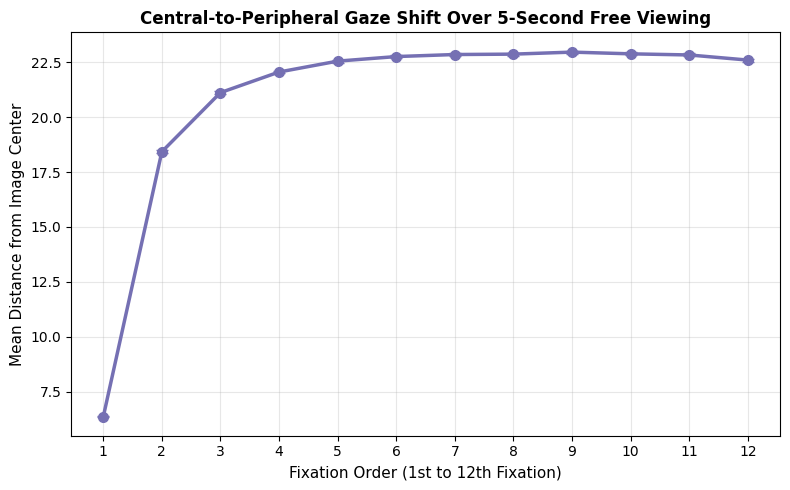

In [17]:
# Check coordinate bounds to find the exact image center automatically
all_x = np.concatenate([np.array(t['X']) for t in data])
all_y = np.concatenate([np.array(t['Y']) for t in data])
center_x = np.nanmax(all_x) / 2.0
center_y = np.nanmax(all_y) / 2.0
print(f"Detected coordinate space: width ~ {np.nanmax(all_x):.0f}, height ~ {np.nanmax(all_y):.0f}")

# Measure average distance from the center for Fixations 1 through 12
max_steps = 12
step_means = []
step_sems = []

for step in range(max_steps):
    dists = []
    for trial in data:
        if len(trial['X']) > step:
            dx = trial['X'][step] - center_x
            dy = trial['Y'][step] - center_y
            d = np.sqrt(dx*2 + dy*2)
            if not np.isnan(d):
                dists.append(d)
    step_means.append(np.mean(dists))
    step_sems.append(np.std(dists) / np.sqrt(len(dists)))

steps = np.arange(1, max_steps + 1)

plt.figure(figsize=(8, 5))
plt.errorbar(steps, step_means, yerr=step_sems, fmt='-o', color='#7570b3',
             linewidth=2.5, markersize=7, capsize=4)
plt.title('Central-to-Peripheral Gaze Shift Over 5-Second Free Viewing', fontsize=12, fontweight='bold')
plt.xlabel('Fixation Order (1st to 12th Fixation)', fontsize=11)
plt.ylabel('Mean Distance from Image Center', fontsize=11)
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figure2_center_bias_trajectory.png', dpi=300)
plt.show()

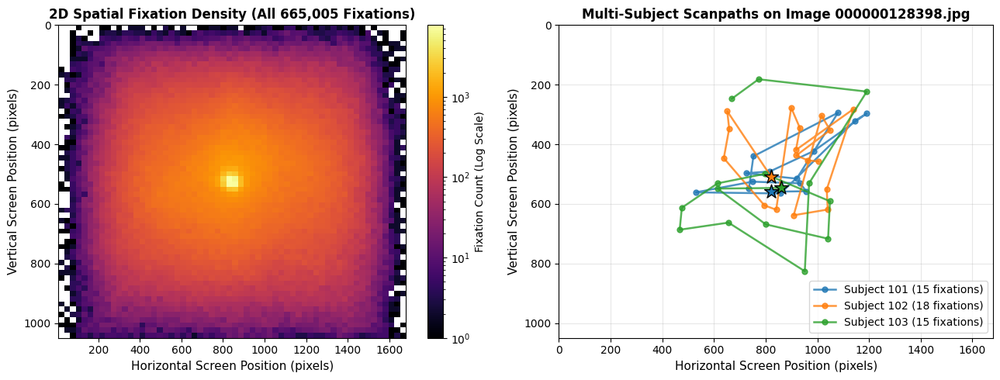

In [18]:
from matplotlib.colors import LogNorm

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Panel: 2D Spatial Heatmap (Log scale reveals both central peak & peripheral spread)
valid = (~np.isnan(all_x)) & (~np.isnan(all_y))
counts, xedges, yedges, im = ax1.hist2d(all_x[valid], all_y[valid], bins=60, cmap='inferno', norm=LogNorm())
plt.colorbar(im, ax=ax1, label='Fixation Count (Log Scale)')
ax1.invert_yaxis()
ax1.set_title('2D Spatial Fixation Density (All 665,005 Fixations)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Horizontal Screen Position (pixels)', fontsize=11)
ax1.set_ylabel('Vertical Screen Position (pixels)', fontsize=11)

# Right Panel: Compare 3 Human Subjects Viewing the Exact Same Image
first_trial = next(iter(data))
sample_img = first_trial['name']
same_img_trials = [t for t in data if t['name'] == sample_img][:3]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx, trial in enumerate(same_img_trials):
    x = np.array(trial['X'])
    y = np.array(trial['Y'])
    c = colors[idx % len(colors)]
    ax2.plot(x, y, '-o', color=c, alpha=0.8, linewidth=1.8, markersize=5,
             label=f"Subject {trial['subject']} ({len(x)} fixations)")
    ax2.scatter(x.item(0), y.item(0), color=c, s=180, marker='*', edgecolor='black', zorder=5)

ax2.set_xlim(0, 1680)
ax2.set_ylim(1050, 0)
ax2.set_title(f'Multi-Subject Scanpaths on Image {sample_img}', fontsize=12, fontweight='bold')
ax2.set_xlabel('Horizontal Screen Position (pixels)', fontsize=11)
ax2.set_ylabel('Vertical Screen Position (pixels)', fontsize=11)
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figure3_scanpaths_and_heatmap.png', dpi=300)
plt.show()